# Image segmentation

Ta muốn đo diện tích vùng mực trên ảnh bài làm. Một box quanh chữ còn chứa nhiều nền trắng, nên detection chưa cho diện tích chính xác. Image segmentation gán nhãn cho từng điểm ảnh. Câu hỏi xuyên suốt là: làm sao giữ được biên nhỏ khi encoder giảm độ phân giải, và làm sao chấm một mask có phần nền chiếm gần hết ảnh?

> **Mục tiêu sau bài này**
>
> - Phân biệt semantic và instance segmentation, chọn loại nhãn và model theo đầu ra đề yêu cầu.
> - Tính Dice/IoU, giải thích vì sao pixel accuracy đánh lừa và vì sao cách gộp điểm đổi kết quả.
> - Viết U-Net nhỏ, kiểm shape khi phóng to và nối skip, huấn luyện trên mask tự tạo.
> - Mã hóa/giải mã RLE đúng thứ tự, đưa mask về kích thước gốc trước khi nộp.

## Mask trả lời một câu hỏi cho mỗi điểm

Semantic segmentation cho lớp ở từng pixel, chẳng hạn nền, mực, giấy. Hai vật thể cùng lớp mang cùng ID. Instance segmentation tách ID cho từng vật thể, dù chúng cùng lớp. Nếu cần đếm hai chai chạm nhau, semantic mask “chai” chưa đủ để chắc chắn tách chúng. Phân đoạn toàn cảnh (panoptic) gộp hai yêu cầu: mọi pixel có lớp, và những vật đếm được như người, xe còn có ID riêng. Mask cũng là số đo: hồ 400 pixel, mỗi pixel ứng với ô $5 \times 5$ m, rộng khoảng 10 000 m².



Instance mask phải giữ ranh giới giữa các vật thể cùng lớp, nên cần model có khái niệm “từng vật”. Một cách phổ biến là Mask R-CNN: lấy detector hai giai đoạn Faster R-CNN của bài 5.5 (RPN đề xuất vùng từ các anchor, rồi phân loại và chỉnh box từng vùng) và thêm một nhánh dự đoán mask nhị phân nhỏ, cỡ $28\times28$, bên trong mỗi box. Mỗi vật thể nhận lớp, box, score và mask riêng, nên hai chai chạm nhau vẫn là hai instance. U-Net trong bài này là model semantic: mỗi pixel nhận một lớp, không có ID vật thể.

**Hỏi nhanh.** Ảnh có hai chai chạm nhau, và mọi vật thể đều là chai. Từ instance mask có dựng lại được semantic mask không? Còn chiều ngược lại thì sao?

- A. Cả hai chiều đều dựng lại được
- B. Từ instance ra semantic được, chiều ngược lại thì không chắc
- C. Từ semantic ra instance được, chiều ngược lại thì không chắc
- D. Không chiều nào dựng lại được

<details><summary>Đáp án</summary>

B. Từ instance ra semantic được, chiều ngược lại thì không chắc

Instance mask có ID 1 và 2 cho hai chai. Đặt mọi ID khác 0 thành lớp “chai” là ra semantic mask. Semantic mask thì chỉ còn một vùng “chai”, và đường ranh giữa hai chai chạm nhau đã mất. Muốn tách lại phải có thêm thông tin, như box hay một model instance. Vì vậy nhãn instance đắt hơn, nhưng phục vụ được cả hai loại bài.

</details>

Với bài nhị phân vùng mực, đầu ra thường là một logit cho mỗi pixel: `(N,1,H,W)`. `BCEWithLogitsLoss` nhận logits và target float cùng shape. Khi suy luận, sigmoid thành xác suất rồi threshold thành mask. Với nhiều lớp loại trừ nhau, logits là `(N,K,H,W)`, target là `(N,H,W)` long, dùng cross-entropy rồi argmax theo chiều lớp: 21 lớp trên ảnh $512 \times 512$ cho logits $(N, 21, 512, 512)$. Mask lưu dạng ảnh thường mang 0/255; phải đổi về 0/1 kiểu long trước cross-entropy, vì 255 vượt quá số lớp.

**Hỏi nhanh.** Mask 3 lớp, gồm 0 là nền, 1 là giấy, 2 là mực, được đọc thành tensor float shape `(N, 1, H, W)`. Logits có shape `(N, 3, H, W)`. Gọi `nn.CrossEntropyLoss()(logits, masks)` thì báo lỗi. Sửa thế nào?

- A. Dùng `masks.squeeze(1).long()` để target có shape `(N, H, W)`
- B. Đổi head còn 1 kênh để logits khớp `(N, 1, H, W)`
- C. Dùng `BCEWithLogitsLoss` và giữ target 0, 1, 2
- D. Lấy `logits.argmax(1)` trước khi đưa vào loss

<details><summary>Đáp án</summary>

A. Dùng `masks.squeeze(1).long()` để target có shape `(N, H, W)`

Tại mỗi pixel, cross-entropy cần $K$ logits và một ID lớp nguyên, nên target phải là `(N, H, W)` kiểu long. Một kênh logits chỉ đủ cho bài nhị phân, không chứa được ba lớp. BCE đòi target cùng shape với logits và coi mỗi giá trị là xác suất trong $[0, 1]$, nên target 0, 1, 2 vô nghĩa. Argmax cho ra ID nguyên, cắt mất gradient và bỏ hết thông tin về độ tin.

</details>

Nhãn segmentation đắt hơn nhãn cả ảnh: phải xác định từng pixel hoặc vùng. Biên có thể mơ hồ do bóng, mờ hoặc chính sách annotation. Model chỉ có thể học theo quy tắc nhãn đã cung cấp; cần xem vài cặp ảnh–mask ở độ phân giải thật.



## Vì sao accuracy chưa đủ?

Giả sử 99% pixel là nền. Dự đoán tất cả nền có pixel accuracy 99% nhưng bỏ mọi vùng mực. Ta cần metric đo chồng lấn vùng mục tiêu.

Với $P$ là tập pixel dự đoán foreground, $G$ là tập thật:

$$\operatorname{IoU}=\frac{|P\cap G|}{|P\cup G|},\qquad
\operatorname{Dice}=\frac{2|P\cap G|}{|P|+|G|}.$$

Viết bằng TP, FP, FN: IoU $=\mathrm{TP}/(\mathrm{TP}+\mathrm{FP}+\mathrm{FN})$, Dice $=2\mathrm{TP}/(2\mathrm{TP}+\mathrm{FP}+\mathrm{FN})$. TN không xuất hiện, nên nhiều nền đúng không che hết lỗi foreground.

**Hỏi nhanh.** Ảnh có 1% pixel là foreground, còn model đoán toàn nền. Pixel accuracy và Dice của foreground lần lượt bằng bao nhiêu?

- A. 99% và 0.99
- B. 99% và 1
- C. 99% và 0
- D. 0% và 0

<details><summary>Đáp án</summary>

C. 99% và 0

Accuracy đếm cả TN, nên vẫn được 99%. Dice không có TN. Ở đây TP bằng 0 còn FN lớn hơn 0, nên Dice bằng $0/(0 + 0 + \mathrm{FN}) = 0$. 0.99 là gán nhầm accuracy cho Dice. Dice bằng 1 chỉ khi **cả hai** mask đều rỗng, còn ở đây mask thật có foreground. Accuracy 0% là quên rằng những pixel nền đoán đúng cũng được tính.

</details>

### Ví dụ tính tay

Ground truth `[1,1,1,0]`, prediction `[1,1,0,1]` có TP = 2, FP = 1, FN = 1. IoU $2/4=0.5$, Dice $4/6=2/3$. Với mask không rỗng, Dice $=2\operatorname{IoU}/(1+\operatorname{IoU})$, nên hai chỉ số đi cùng chiều nhưng giá trị khác. Ví dụ mask dự đoán 30 pixel, mask thật 20, chung 15 cho Dice $30/50 = 0.6$; còn IoU 0.6 ứng với Dice $1.2/1.6 = 0.75$. Ảnh vệ tinh 95% nền mà model đoán toàn nền thì pixel accuracy 95% nhưng IoU của lớp “nhà” bằng 0.

In [ ]:
import numpy as np

def mask_scores(predicted, target):
    predicted = np.asarray(predicted, dtype=bool)
    target = np.asarray(target, dtype=bool)
    assert predicted.shape == target.shape
    intersection = np.logical_and(predicted, target).sum()
    union = np.logical_or(predicted, target).sum()
    total = predicted.sum() + target.sum()
    iou = 1.0 if union == 0 else intersection / union
    dice = 1.0 if total == 0 else 2 * intersection / total
    return float(iou), float(dice)

print(tuple(round(v, 4) for v in mask_scores([1, 1, 0, 1], [1, 1, 1, 0])))
print(mask_scores(np.zeros(4), np.zeros(4)))
print(mask_scores([0, 0, 0, 0], [1, 0, 0, 0]))

(0.5, 0.6667)
(1.0, 1.0)
(0.0, 0.0)


Hàm trên cho điểm 1 khi cả hai mask đều rỗng: không có pixel foreground nào để đoán sai. Scorer của đề có thể bỏ ảnh hoặc lớp rỗng, hoặc dùng quy tắc khác; khi nhiều ảnh không có vật thể, chính quy tắc này quyết định một phần lớn điểm. Cách gộp cũng đổi kết quả: mean Dice theo ảnh cho mỗi ảnh một phiếu, còn Dice tính sau khi gộp pixel của mọi ảnh cho vùng lớn trọng lượng lớn hơn.



**Hỏi nhanh.** Ảnh A có vật lớn, với TP = 90, FP = 10, FN = 0. Ảnh B có vật nhỏ, với TP = 1, FP = 0, FN = 9. Mean Dice theo ảnh và Dice sau khi gộp pixel của hai ảnh xấp xỉ bao nhiêu?

- A. Theo ảnh 0.56, gộp pixel 0.91
- B. Theo ảnh 0.91, gộp pixel 0.56
- C. Cả hai cách cùng xấp xỉ 0.56
- D. Cả hai cách cùng xấp xỉ 0.91

<details><summary>Đáp án</summary>

A. Theo ảnh 0.56, gộp pixel 0.91

Dice(A) $= 180/190 \approx 0.947$ và Dice(B) $= 2/11 \approx 0.182$, nên trung bình khoảng 0.565. Khi gộp pixel thì TP = 91, FP = 10, FN = 9, và Dice $= 182/201 \approx 0.905$. Vật lớn chiếm gần hết số pixel, nên cách gộp gần như che mất lỗi bỏ sót vật nhỏ, còn mean theo ảnh làm lỗi ấy lộ ra. Cả hai cách đều hợp lệ, nhưng chọn model thì phải theo đúng cách đề chấm.

</details>



## U-Net giữ cả ngữ cảnh lẫn chi tiết

Encoder giảm độ phân giải để đọc ngữ cảnh rộng. Decoder tăng độ phân giải để xuất mask. Nếu chỉ phóng to biểu diễn nhỏ, thông tin biên đã mất không tự trở lại. U-Net nối feature map encoder với decoder ở độ phân giải tương ứng, thường bằng phép nối kênh (concatenate).



Khác residual $x+F(x)$ giữ nguyên số kênh, skip của U-Net `cat` hai tensor theo chiều kênh: số kênh cộng lại, còn $N,H,W$ của hai tensor phải khớp. Conv ngay sau phép nối phải được khai báo với tổng số kênh đó; mạng trong bài nối 4 kênh skip với 8 kênh từ đáy thành 12 kênh.

**Hỏi nhanh.** Sau khi phóng to, decoder có 64 kênh. Skip từ encoder có 32 kênh, cùng $H$ và $W$. Sau `torch.cat(..., dim=1)`, conv kế tiếp phải nhận bao nhiêu kênh vào?

- A. 32
- B. 64
- C. 96
- D. 128

<details><summary>Đáp án</summary>

C. 96

Nối theo kênh thì số kênh cộng lại: $64 + 32 = 96$. 128 đến từ việc nhớ máy móc rằng nối skip thì gấp đôi. Điều đó chỉ đúng khi decoder và skip có cùng số kênh, như U-Net gốc. 64 là quên kênh của skip, như thể phép nối là phép cộng residual. 32 là chỉ đếm skip.

</details>

Decoder phóng to bằng một trong hai cách. Nội suy (`F.interpolate`, nearest hoặc bilinear) không có tham số học. Transposed convolution (`nn.ConvTranspose2d`) có kernel học được; với kernel $k$, stride $s$, padding $p$, chiều ra là $H_{\text{out}}=(H-1)s-2p+k$ (cộng thêm `output_padding` nếu đặt, mặc định 0), nên cấu hình hay gặp $k=s=2$, $p=0$ cho đúng $2H$. Ngược với conv thường, stride ở đây làm ảnh **lớn** lên: `nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)` đưa `(1, 64, 16, 16)` thành `(1, 32, 32, 32)`. Với 4 lần pooling, cạnh ảnh nên chia hết cho 16; ảnh $101 \times 101$ bị làm tròn xuống ở mỗi lần pooling nên lúc nối hai tensor lệch kích thước, trừ khi pad ảnh lên 112 hoặc phóng theo đúng size của skip như mục sau.

**Hỏi nhanh.** `nn.ConvTranspose2d(8, 4, kernel_size=2, stride=2)` nhận tensor `(N, 8, 6, 6)`. Đầu ra có shape gì?

- A. `(N, 4, 3, 3)`
- B. `(N, 4, 7, 7)`
- C. `(N, 8, 12, 12)`
- D. `(N, 4, 12, 12)`

<details><summary>Đáp án</summary>

D. `(N, 4, 12, 12)`

Cạnh mới là $(6 - 1)\cdot 2 - 0 + 2 = 12$, và số kênh ra là tham số thứ hai, tức 4. `(N, 4, 3, 3)` là áp công thức của conv thường, nơi stride 2 làm ảnh nhỏ đi. `(N, 4, 7, 7)` là quên stride, coi như stride 1. `(N, 8, 12, 12)` giữ số kênh vào, tức nhầm vai trò của hai tham số đầu.

</details>

[Bài báo U-Net](https://arxiv.org/abs/1505.04597) (Ronneberger và cộng sự, 2015) giảm độ phân giải bốn lần, số kênh tăng từ 64 lên 1024, và dùng conv không padding: ảnh vào $572\times572$ cho mask $388\times388$, nên feature map của encoder phải được cắt phần giữa (crop) trước khi nối. Mạng trong bài chỉ có một mức, conv có padding và phóng to bằng nội suy, đủ nhỏ để train trên CPU.

U-Net chỉ gồm conv, pooling và phép phóng to, không có tầng fully connected gắn với kích thước ảnh, nên cùng bộ trọng số chạy được trên ảnh lớn hơn lúc train. Giới hạn thật là bộ nhớ: ảnh vệ tinh hay ảnh hiển vi vài nghìn pixel mỗi chiều có thể không vừa GPU. Khi đó cắt ảnh thành các tile chồng lấn, dự đoán từng tile, rồi ghép logits và chỉ giữ (hoặc lấy trung bình) phần giữa mỗi tile, vì pixel sát mép tile thiếu ngữ cảnh ở một phía.

## Dữ liệu nhỏ để nhìn được sai đúng

Ảnh tự tạo có hình chữ nhật sáng, nhiễu nhỏ và nền tối; mask đúng là hình chữ nhật. Train và validation dùng seed khác. Độ sáng gần như cho thẳng nhãn, nên đây là bài dễ: nó dùng để kiểm cả đường đi từ dữ liệu, shape, loss đến metric, chưa phải để so sánh model.

In [ ]:
import torch
from torch import nn
import torch.nn.functional as F

torch.set_num_threads(1)
torch.manual_seed(56)

def make_rectangles(count, seed):
    rng = np.random.default_rng(seed)
    masks = np.zeros((count, 1, 12, 12), dtype=np.float32)
    for index in range(count):
        row, col = rng.integers(1, 6, size=2)
        height, width = rng.integers(3, 6, size=2)
        masks[index, 0, row:row + height, col:col + width] = 1
    noise = rng.normal(0, 0.08, masks.shape).astype(np.float32)
    images = np.clip(0.1 + 0.8 * masks + noise, 0, 1)
    return torch.from_numpy(images), torch.from_numpy(masks)

train_x, train_y = make_rectangles(24, 10)
valid_x, valid_y = make_rectangles(8, 11)
print(tuple(train_x.shape), tuple(train_y.shape))
print(int(train_y[0].sum()), int(valid_y[0].sum()))

(24, 1, 12, 12) (24, 1, 12, 12)
9 20


Hai tổng cuối là số pixel foreground trong hai mask mẫu: hình chữ nhật $3\times3$ và $4\times5$. Nhìn chúng phát hiện ngay nhãn vô tình toàn 0, hoặc nhãn mang giá trị lạ, trước khi train. Mask ở đây là float 0/1 vì `BCEWithLogitsLoss` cần target float; bài nhiều lớp dùng ID kiểu long như đã nói.

**Hỏi nhanh.** Mask đọc từ PNG mang giá trị 0 và 255. Mask mẫu là hình chữ nhật 9 pixel, nhưng `int(train_y[0].sum())` lại in ra 2295. Sai ở đâu, và `BCEWithLogitsLoss` sẽ ra sao?

- A. Không sai, BCE tự đưa target về đoạn $[0, 1]$
- B. Target 255 nằm ngoài $[0, 1]$, nên loss âm và giảm mãi không có đáy
- C. Mask bị đếm trùng pixel, cần `np.unique` trước khi train
- D. Target 255 khiến BCE báo lỗi ngay ở bước đầu tiên

<details><summary>Đáp án</summary>

B. Target 255 nằm ngoài $[0, 1]$, nên loss âm và giảm mãi không có đáy

$2295 = 9\cdot 255$. BCE không kiểm miền của target và cũng không tự chia. Với $y = 255$, hệ số $1 - y$ trong số hạng $-(1 - y)\log(1 - \sigma(z))$ thành $-254$, nên loss giảm mãi khi $z$ tăng. Thử nhanh với logits `[3, 10, -2]` và target `[255, 255, 0]` thì loss khoảng $-1100.6$, và không có lỗi nào được báo. Cũng không có chuyện đếm trùng: tổng lớn vì mỗi pixel mang giá trị 255. Sửa bằng `(mask > 0).float()` trước khi train.

</details>

## Viết và train U-Net nhỏ

Max pooling làm tròn xuống, nên với chiều lẻ, phóng gấp đôi không trở về đúng kích thước cũ: 13 thành 6, rồi 6 thành 12. Vì vậy `interpolate` nhận thẳng `size` của skip thay vì `scale_factor=2`. Ảnh $12\times12$ của bài chia hết cho 2, nhưng cùng code vẫn nối đúng với ảnh có chiều lẻ.

In [ ]:
class TinyUNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.encode = nn.Sequential(nn.Conv2d(1, 4, 3, padding=1), nn.ReLU())
        self.middle = nn.Sequential(nn.Conv2d(4, 8, 3, padding=1), nn.ReLU())
        self.decode = nn.Sequential(nn.Conv2d(12, 4, 3, padding=1), nn.ReLU())
        self.output = nn.Conv2d(4, 1, 1)

    def forward(self, images):
        skip = self.encode(images)
        low = self.middle(F.max_pool2d(skip, 2))
        up = F.interpolate(low, size=skip.shape[-2:], mode="nearest")
        joined = torch.cat([skip, up], dim=1)
        return self.output(self.decode(joined))

model = TinyUNet()
optimizer = torch.optim.Adam(model.parameters(), lr=0.02)
criterion = nn.BCEWithLogitsLoss()
print("logits:", tuple(model(train_x[:2]).shape))
for step in range(80):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(train_x), train_y)
    loss.backward()
    optimizer.step()

model.eval()
with torch.no_grad():
    valid_logits = model(valid_x)
    valid_loss = criterion(valid_logits, valid_y).item()
    masks = valid_logits.sigmoid() >= 0.5
scores = [mask_scores(masks[i, 0].numpy(), valid_y[i, 0].numpy())
          for i in range(len(valid_y))]
print("valid BCE:", round(valid_loss, 4))
print("mean IoU, Dice:", np.mean(scores, axis=0).round(4).tolist())

logits: (2, 1, 12, 12)
valid BCE: 0.0034
mean IoU, Dice: [0.9922, 0.996]


Dòng đầu xác nhận logits có đúng shape `(2,1,12,12)` của mask. BCE validation là 0.0034; mean IoU 0.9922 và mean Dice 0.996 lấy trung bình theo 8 ảnh validation. Loss là thứ được tối ưu, IoU/Dice là thứ được chấm, và cả hai ở đây đều đo trên validation. Điểm gần 1 phản ánh dữ liệu sinh rất sạch; vùng mực thật mờ, chồng lên dòng kẻ hoặc có ánh sáng không đều khó hơn nhiều.



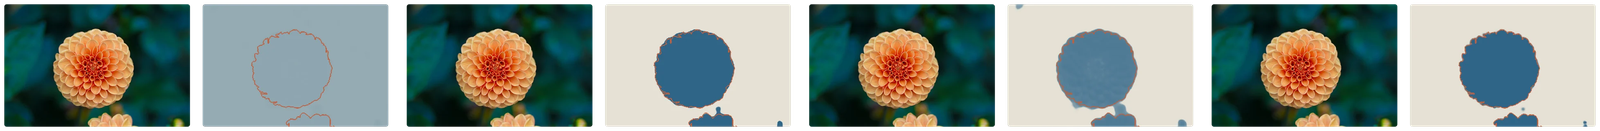

Dice cũng dùng làm loss được nếu thay tập nhị phân bằng xác suất $p_i=\sigma(z_i)$:

$$L_{\text{Dice}}=1-\frac{2\sum_i p_i g_i+\varepsilon}{\sum_i p_i+\sum_i g_i+\varepsilon},$$

với $g_i\in\{0,1\}$ là nhãn và $\varepsilon$ nhỏ (thường bằng 1) để mask rỗng không gây chia cho 0. Bản mềm này có đạo hàm theo $p_i$; threshold trước khi tính thì mất đạo hàm. Pixel nền đoán đúng ($p_i\approx0$, $g_i=0$) gần như không góp gì vào tử lẫn mẫu, nên Dice loss không bị phần nền lớn lấn át như BCE lấy trung bình theo pixel. Nhiều đội cộng BCE với Dice loss; tổ hợp nào tốt hơn do validation quyết định, vì tối ưu Dice loss không bảo đảm Dice sau threshold cao nhất.

**Hỏi nhanh.** Một đội viết `loss = 1 - dice((model(x).sigmoid() >= 0.5).float(), y)`. Gọi `loss.backward()` thì báo *element 0 of tensors does not require grad*. Sửa thế nào mới đúng?

- A. Gọi `.requires_grad_()` trên mask nhị phân trước khi tính
- B. Hạ threshold từ 0.5 xuống 0.3 để mask bớt rỗng
- C. Bọc phần tính loss trong `with torch.no_grad():`
- D. Tính Dice mềm trên xác suất `sigmoid`, bỏ threshold

<details><summary>Đáp án</summary>

D. Tính Dice mềm trên xác suất `sigmoid`, bỏ threshold

Phép so sánh `>=` tạo ra tensor không nối với graph, nên loss không có đường đạo hàm về model. Thêm `.requires_grad_()` thì hết lỗi, nhưng gradient dừng ngay ở mask đó, và tham số model vẫn không nhận được gì. Gradient của logits vẫn là `None`. Đổi threshold không thay đổi bản chất bậc thang. `no_grad` thì tắt hẳn việc ghi graph. Threshold chỉ dùng khi suy luận và khi chấm.

</details>

Cùng `TinyUNet` này được đóng gói thành [recipe fine-tune trên ảnh và mask cục bộ](recipes/README.md). Dữ liệu cần bốn thư mục `train/images`, `train/masks`, `valid/images`, `valid/masks`; ảnh và mask cùng tên, mask chỉ mang 0/255 hoặc 0/1. Lệnh không có `--run` chỉ kiểm dữ liệu. Thêm `--run` cùng `--from-scratch`, hoặc cùng checkpoint kèm SHA-256, thì script resize ảnh bằng bilinear và mask bằng nearest, train trên CPU với batch 2, ghi checkpoint có mean Dice validation tốt nhất vào tệp `--output` mới rồi nạp lại để suy luận thử một batch. Số in ra mỗi epoch là mean Dice validation trên chính dữ liệu đó; khi so các cấu hình, ghi kèm split, kích thước ảnh và số epoch.

## RLE: dùng lại kỹ năng xử lý dãy

Run-length encoding (RLE) lưu các đoạn foreground liên tiếp sau khi trải mask. Bài dùng một quy ước cụ thể: trải **theo hàng** (row-major), vị trí bắt đầu tính từ 1, mỗi cặp là start và length. Đó không phải chuẩn chung: COCO trải theo cột và ghi xen kẽ độ dài các run 0 và run 1; nhiều cuộc thi dùng cặp start–length nhưng đánh số pixel từ trên xuống dưới rồi mới sang phải, tức trải theo cột.

Mask $\begin{bmatrix}0&1&0\\1&1&0\end{bmatrix}$ trải theo hàng là `0,1,0,1,1,0`, nên RLE là `[2,1,4,2]`. Trải theo cột cho `0,1,1,1,0,0`, ra `[2,3]`. Cùng mask nhưng bytes đầu ra khác.



In [ ]:
def encode_rle(mask):
    values = np.asarray(mask, dtype=np.uint8).ravel(order="C")
    padded = np.r_[0, values, 0]
    changes = np.flatnonzero(padded[1:] != padded[:-1]) + 1
    changes[1::2] -= changes[::2]
    return changes.tolist()

def decode_rle(runs, shape):
    assert len(runs) % 2 == 0
    flat = np.zeros(np.prod(shape), dtype=np.uint8)
    for start, length in zip(runs[::2], runs[1::2]):
        assert 1 <= start and length > 0 and start - 1 + length <= len(flat)
        flat[start - 1:start - 1 + length] = 1
    return flat.reshape(shape, order="C")

small_mask = np.array([[0, 1, 0], [1, 1, 0]], dtype=np.uint8)
runs = encode_rle(small_mask)
print(runs)
print(np.array_equal(small_mask, decode_rle(runs, small_mask.shape)))
print(encode_rle(np.zeros((2, 3), dtype=np.uint8)))
print(encode_rle(np.ones((2, 3), dtype=np.uint8)))

[2, 1, 4, 2]
True
[]
[1, 6]


Round trip `True` kiểm encoder/decoder nhất quán. Nó chưa chứng minh format khớp đề, vì hai hàm có thể cùng dùng sai thứ tự. Đối chiếu sample chuẩn và vẽ mask giải mã mới kiểm được hợp đồng bên ngoài.

**Hỏi nhanh.** Mask `[[1, 0], [1, 1]]` được mã hóa theo hàng thành `[1, 1, 3, 2]`, nhưng scorer lại giải mã theo cột. Scorer thấy mask nào?

- A. `[[1, 0], [1, 1]]`
- B. Không thấy mask nào, vì scorer báo lỗi định dạng
- C. `[[1, 1], [0, 1]]`
- D. `[[0, 1], [0, 0]]`

<details><summary>Đáp án</summary>

C. `[[1, 1], [0, 1]]`

Scorer bật các vị trí 1, 3 và 4, nhưng đánh số theo cột: 1 là ô (0, 0), 2 là (1, 0), 3 là (0, 1), 4 là (1, 1). Kết quả là `[[1, 1], [0, 1]]`, đúng bằng ma trận chuyển vị. Chuỗi vẫn hợp lệ nên không có lỗi nào, chỉ có điểm thấp. Mask chỉ giữ nguyên khi cả hai phía dùng cùng thứ tự. `[[0, 1], [0, 0]]` là phần bù, không liên quan đến thứ tự đọc.

</details>

## Đổi kích thước mask

Mask là nhãn rời rạc, nên khi resize phải dùng nearest: bilinear tạo giá trị trung gian giữa hai lớp. Khi đưa dự đoán về kích thước ảnh gốc, phóng logits hoặc xác suất (bilinear được, vì chúng là số liên tục) rồi mới threshold; RLE nộp bài phải mã hóa mask ở đúng shape gốc mà scorer dùng. Lệch một pixel giữa ảnh và mask, do crop hoặc padding không đồng bộ, gây lỗi lớn ở nét mảnh. Connected components chỉ tách được những vùng không nối nhau, nên không thay được instance segmentation khi vật thể chạm nhau.

**Hỏi nhanh.** Mask một hàng `[0, 0, 2, 2]`, với 0 là nền, 1 là giấy, 2 là mực, được phóng lên 8 cột bằng bilinear thành `[0, 0, 0, 0.5, 1.5, 2, 2, 2]`. Sau `.long()` thì thành `[0, 0, 0, 0, 1, 2, 2, 2]`. Sửa thế nào?

- A. Resize mask bằng nearest để chỉ chép lại nhãn
- B. Dùng `.round()` thay `.long()` để làm tròn đúng
- C. Đặt `align_corners=True` cho nội suy chính xác
- D. Đổi mask sang `float64` trước khi nội suy

<details><summary>Đáp án</summary>

A. Resize mask bằng nearest để chỉ chép lại nhãn

Bilinear lấy trung bình hai lớp 0 và 2 nên sinh ra 1, tức lớp “giấy”, thứ không hề có ở đó. `.round()` chỉ cứu được ví dụ này nhờ may mắn, vì 0.5 thành 0 và 1.5 thành 2. Giữa lớp 0 và lớp 3 thì nó vẫn sinh ra 1 và 2. `align_corners` chỉ dời vị trí lấy mẫu, `float64` chỉ tăng độ chính xác, nên cả hai vẫn nội suy giữa các ID.

</details>



## Khi đi thi

- **Viết lại scorer trước khi train.** Đọc đề chấm Dice hay IoU, trung bình theo ảnh, theo lớp hay gộp pixel, ảnh và lớp rỗng tính thế nào; thử scorer cục bộ trên mask rỗng, mask kín và một ví dụ tính tay.
- **Chồng mask lên vài ảnh.** Mask 0/255, mask lệch vài pixel, lật trục hay ghép nhầm tệp đều lộ ra sau vài giây nhìn, trước khi tốn GPU.
- **Đếm ảnh rỗng.** Khi nhiều ảnh không có vật thể, vài pixel dương giả đủ biến điểm 1 thành 0; thử bỏ vùng dự đoán nhỏ hơn một diện tích tối thiểu, chọn ngưỡng ấy cùng threshold trên validation theo đúng metric của đề.
- **Cân độ phân giải với ngân sách GPU.** Vật thể mảnh biến mất khi thu nhỏ ảnh; nếu ảnh gốc không vừa bộ nhớ, dự đoán theo tile chồng lấn rồi ghép logits.
- **Kiểm submission trước khi nộp.** Đưa logits về kích thước gốc rồi threshold, mã hóa RLE đúng thứ tự trải và chỉ số bắt đầu, so với sample chính thức và giải mã thử vài dòng.

## Tóm tắt

- Semantic segmentation cho mỗi pixel một lớp; instance segmentation tách thêm từng vật thể, chẳng hạn bằng Mask R-CNN. Loại nhãn và model chọn theo đầu ra đề yêu cầu.
- Dice/IoU đo chồng lấn foreground và không đếm TN; quy tắc mask rỗng và cách gộp (theo ảnh, theo lớp, gộp pixel) có thể đổi điểm rất nhiều.
- U-Net nối ngữ cảnh ở độ phân giải thấp với chi tiết từ encoder; khi nối, số kênh cộng lại còn $H,W$ phải khớp.
- Train bằng logits với BCE, hoặc Dice mềm trên xác suất; threshold chỉ dùng khi suy luận và chấm.
- RLE chỉ đúng khi thứ tự trải, chỉ số bắt đầu và shape khớp hợp đồng của đề; round trip trong code chưa kiểm được điều đó.

## Kiểm tra cuối bài

**Câu 1.** Đề yêu cầu báo tỉ lệ diện tích của mực, giấy và nền trên mỗi ảnh bài làm, không cần đếm nét chữ. Loại nhãn nào vừa đủ dùng vừa rẻ nhất?

- A. Một nhãn lớp cho cả ảnh
- B. Bounding box quanh từng chữ cái
- C. Semantic mask, mỗi pixel một lớp
- D. Instance mask riêng cho từng nét chữ

<details><summary>Đáp án</summary>

C. Semantic mask, mỗi pixel một lớp

Diện tích là số pixel của từng lớp, nên cần nhãn ở mức pixel, và semantic mask cho đúng điều đó. Nhãn cả ảnh không chứa vị trí. Box quanh chữ ôm cả nền trắng, nên đếm thừa diện tích mực. Instance mask cũng tính được diện tích, nhưng phải tách từng nét, tốn công gán nhãn mà đề không cần.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 210](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=76)

</details>

**Câu 2.** Đề cho ảnh hiển vi và yêu cầu nộp một mask riêng cho từng tế bào. Nhiều tế bào nằm sát, chạm vào nhau. Model nào cho ra đúng dạng đầu ra này?

- A. U-Net một kênh foreground
- B. Mask R-CNN
- C. YOLO
- D. ResNet phân loại ảnh

<details><summary>Đáp án</summary>

B. Mask R-CNN

Mask R-CNN cho mỗi vật thể một box, một lớp, một score và một mask riêng, đúng là instance segmentation. U-Net một kênh chỉ cho một vùng “tế bào” chung, nên các tế bào chạm nhau dính thành một vùng. YOLO cho box, không cho mask. ResNet phân loại chỉ cho một nhãn cho cả ảnh.
Phỏng theo: [NOAI 2025 Singapore · Phần 1 · Câu 15](https://learn.aisingapore.org/wp-content/uploads/2025/10/NOAI-2025-MCQ-Assessment-Questions.pdf#page=3)

</details>

**Câu 3.** Đề chấm bằng IoU, còn notebook in ra Dice. Trên một ảnh validation, Dice của mask dự đoán là 0.8. IoU của cùng cặp mask đó xấp xỉ bao nhiêu?

- A. 0.4
- B. 0.67
- C. 0.8
- D. 0.89

<details><summary>Đáp án</summary>

B. 0.67

Từ Dice $= 2\operatorname{IoU}/(1 + \operatorname{IoU})$ suy ra IoU $= \text{Dice}/(2 - \text{Dice}) = 0.8/1.2 \approx 0.67$. Kiểm bằng số: TP = 4 và FP + FN = 2 cho Dice bằng $8/10$, IoU bằng $4/6$. 0.89 là áp nhầm công thức chiều xuôi lên Dice. 0.4 là chia đôi. 0.8 là coi hai metric như nhau. Quan hệ này đúng cho từng cặp mask. Mean Dice của nhiều ảnh thì không đổi thẳng ra mean IoU được.

</details>

**Câu 4.** Hàm tính mIoU cho segmentation nhiều lớp duyệt từng lớp trên mỗi ảnh. Lớp “xe máy” chỉ có trong 5% số ảnh. Ở một ảnh không có xe máy, model cũng không đoán pixel xe máy nào, nên union của lớp này bằng 0. Xử lý thế nào để mIoU có ý nghĩa nhất?

- A. Bỏ lớp đó khỏi trung bình của ảnh này
- B. Gán IoU = 1 vì model đã đúng khi đoán vắng
- C. Gán IoU = 0 để phạt và ép model học lớp hiếm
- D. Dùng IoU có trọng số theo tần suất pixel

<details><summary>Đáp án</summary>

A. Bỏ lớp đó khỏi trung bình của ảnh này

Khi lớp vắng ở cả hai phía, ảnh này không cho biết gì về khả năng tô lớp đó. Bỏ qua thì mIoU chỉ đo những lớp có mặt. Gán 1 thì 95% số ảnh tặng điểm tuyệt đối cho lớp xe máy, thổi phồng mIoU. Gán 0 thì phạt model dù nó không sai, kéo mIoU xuống. Trọng số theo tần suất pixel làm lớp hiếm gần như biến mất khỏi điểm, ngược với điều cần đo. Scorer chính thức có thể chọn quy ước khác, nên scorer cục bộ phải theo đúng quy ước của đề.
Đề thi: [NOAI 2026 Singapore · Chung kết · Câu 14](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=20)

</details>

**Câu 5.** Một đội bỏ mọi skip connection khỏi U-Net để tiết kiệm bộ nhớ. Mask mới vẫn nằm đúng vùng đại thể, nhưng biên bị nhòe và những nét mảnh 1–2 pixel biến mất. Như vậy skip connection chủ yếu làm việc gì?

- A. Tăng tốc train nhờ gradient đi tắt
- B. Giảm số tham số và bộ nhớ của decoder
- C. Thêm phi tuyến giữa encoder và decoder
- D. Mang chi tiết phân giải cao sang decoder

<details><summary>Đáp án</summary>

D. Mang chi tiết phân giải cao sang decoder

Sau nhiều lần pooling, biểu diễn ở đáy biết có gì và ở vùng nào, nhưng đã mất vị trí chính xác của từng pixel. Phóng to không tạo lại được thông tin ấy. Skip đưa feature map phân giải cao của encoder vào decoder để định vị biên. Đường đi tắt có giúp gradient, nhưng triệu chứng ở đây là mất chi tiết chứ không phải train chậm. Phép nối làm conv của decoder nhận nhiều kênh hơn, tức tăng tham số. Bản thân phép nối là tuyến tính.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 234](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=84)

</details>

**Câu 6.** Ảnh vào $100\times 100$, mọi `Conv2d` có `padding=1`, và mỗi mức encoder max-pool $2\times 2$. Các skip `s1`, `s2`, `s3` có kích thước 100, 50, 25. Đáy `x` có 512 kênh, sau thêm một lần pool nữa.

```py
self.up1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
self.conv1 = nn.Conv2d(512, 256, kernel_size=3, padding=1)
...
x = self.up1(x)
x = torch.cat([x, s3], dim=1)   # dòng A, s3 có 256 kênh
x = self.conv1(x)
```

Dòng A báo *Sizes of tensors must match*. Vì sao?

- A. Pool từ 25 làm tròn xuống 12, nên `up1` chỉ cho 24, lệch với 25
- B. 256 nối 256 thành 512 kênh, `conv1` không nhận được
- C. Phải nối theo `dim=0`, tức theo batch, thay vì theo kênh
- D. Conv không padding làm feature nhỏ dần qua mỗi tầng

<details><summary>Đáp án</summary>

A. Pool từ 25 làm tròn xuống 12, nên `up1` chỉ cho 24, lệch với 25

Kích thước đi $100 \to 50 \to 25 \to 12$, vì max pooling lấy phần nguyên. Transposed conv với kernel và stride bằng 2 cho $2\cdot 12 = 24$, lệch skip 25 một pixel. Số kênh thì khớp, `conv1` nhận đúng 512. Nối theo batch đòi các chiều còn lại khớp, và trộn ảnh với feature. Conv có `padding=1` giữ nguyên kích thước, nên lỗi không đến từ padding. Có ba cách sửa: phóng thẳng về `size=s3.shape[-2:]` như `TinyUNet`, pad thêm một hàng và một cột, hoặc chọn ảnh vào chia hết cho $2^3 = 8$, như 96 hay 104. `nn.Upsample(scale_factor=2)` cũng chỉ cho 24 nên không sửa được. `output_padding=1` cho 25, nhưng chỉ khớp riêng kích thước này.
Phỏng theo: [NOAI 2026 Singapore · Chung kết · Câu 13](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=18)

</details>

**Câu 7.** Mask $3\times 3$ là `[[0, 1, 1], [0, 0, 1], [1, 0, 0]]`. RLE trải mask theo hàng, đánh số từ 1, gộp tối đa các số 1 liên tiếp, và ghi mỗi run thành (start, length). Mã nào đúng?

- A. `[1, 2, 5, 2]`
- B. `[2, 3, 6, 7]`
- C. `[3, 2, 7, 2]`
- D. `[2, 2, 6, 2]`

<details><summary>Đáp án</summary>

D. `[2, 2, 6, 2]`

Trải theo hàng được 0, 1, 1, 0, 0, 1, 1, 0, 0. Có hai run tối đa, bắt đầu ở vị trí 2 và 6, mỗi run dài 2. `[1, 2, 5, 2]` là đếm vị trí từ 0. `[2, 3, 6, 7]` ghi (start, end) thay vì (start, length). `[3, 2, 7, 2]` là kết quả khi trải theo cột, được 0, 0, 1, 1, 0, 0, 1, 1, 0.

</details>

**Câu 8.** Ảnh vệ tinh $4096\times 4096$ cần mask đường đi rộng 2–3 pixel, nhưng GPU chỉ chạy được tile $512\times 512$. Cắt thành 64 tile không chồng nhau rồi ghép lại thì mask tốt ở giữa tile, nhưng hay bị đứt dọc theo các đường cắt. Nên sửa theo hướng nào?

- A. Resize cả ảnh về $512\times 512$, dự đoán một lần
- B. Chọn threshold riêng cho từng tile
- C. Train thêm vài epoch trên các tile sát mép ảnh
- D. Cắt tile chồng lấn, ghép logits ở phần giữa tile

<details><summary>Đáp án</summary>

D. Cắt tile chồng lấn, ghép logits ở phần giữa tile

Pixel sát mép tile thiếu ngữ cảnh ở một phía, nên logits kém tin cậy. Tile chồng lấn cho mỗi pixel ít nhất một lần nằm gần giữa tile. Ta lấy trung bình logits hoặc chỉ giữ vùng giữa, rồi mới threshold. Thu ảnh 8 lần làm đường rộng 2–3 pixel còn chưa tới nửa pixel, tức mất hẳn. Threshold riêng cho từng tile còn tạo thêm vết nối. Train thêm cũng không cho pixel ở mép có thêm ngữ cảnh lúc suy luận.

</details>

**Câu 9.** Model được train trên ảnh resize về $256\times 256$. Ảnh test gốc cao 768, rộng 1024, và scorer giải mã RLE theo shape gốc. Đội mã hóa thẳng mask $256\times 256$ mà model dự đoán. Phải làm gì mới đúng?

- A. Không cần làm gì, scorer tự co giãn RLE theo tỉ lệ ảnh
- B. Nhân mọi start và length với 12 là khớp shape gốc
- C. Phóng logits về shape gốc, threshold rồi mới mã hóa
- D. Đổi sang trải theo cột là đủ khớp với ảnh gốc

<details><summary>Đáp án</summary>

C. Phóng logits về shape gốc, threshold rồi mới mã hóa

RLE ghi vị trí trong mảng đã trải của một shape cụ thể. Shape $256\times 256$ có 65 536 vị trí, còn ảnh gốc có 786 432. Scorer không biết mask đã bị co. Nhân với $12 = 786\,432/65\,536$ giữ đúng tổng diện tích nhưng sai vị trí: một run dài $L$ trên một hàng phải thành ba run dài $4L$ trên ba hàng liền nhau, chứ không phải một run dài $12L$. Thứ tự trải không liên quan đến kích thước. Phóng logits bằng bilinear rồi threshold cho biên mượt hơn so với phóng mask nhị phân bằng nearest.

</details>

**Câu 10.** Tập test có 100 ảnh, trong đó 60 ảnh không có vết nứt. Scorer tính Dice từng ảnh rồi lấy trung bình. Ảnh nào có cả mask thật và mask dự đoán đều rỗng thì được 1. Một bài nộp toàn mask rỗng đạt bao nhiêu?

- A. 1
- B. 0.6
- C. 0.4
- D. 0

<details><summary>Đáp án</summary>

B. 0.6

60 ảnh rỗng cả hai phía được 1. 40 ảnh có vết nứt có TP bằng 0, nên Dice bằng 0. Trung bình là $(60\cdot 1 + 40\cdot 0)/100 = 0.6$. 0.4 là đếm ngược hai nhóm. 1 và 0 là quên hẳn một nhóm. Chiều ngược lại cũng đáng nhớ: chỉ vài pixel dương giả trên một ảnh rỗng là ảnh đó rơi từ 1 xuống 0. Vì vậy với scorer kiểu này, bỏ những vùng dự đoán quá nhỏ, hoặc thêm một classifier quyết định ảnh có vết nứt hay không, thường đáng công.

</details>

## Đọc thêm

- Ronneberger, Fischer, Brox — [U-Net](https://arxiv.org/abs/1505.04597): xem vai trò đường nối giữa encoder và decoder.
- [PyTorch — BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html): kiểm kiểu target, shape và cách ghép sigmoid.
- He, Gkioxari, Dollár, Girshick — [Mask R-CNN](https://arxiv.org/abs/1703.06870): xem nhánh mask được gắn vào detector hai giai đoạn thế nào.
- [COCO mask API](https://github.com/cocodataset/cocoapi/blob/master/PythonAPI/pycocotools/mask.py): đối chiếu format RLE của COCO (trải theo cột, counts xen kẽ) với quy ước start–length trong bài.

Nguồn ảnh: ảnh hoa là ảnh mẫu `flower.jpg` kèm scikit-learn (vultilion, Flickr, CC BY 2.0); mask trong hình được đặt bằng ngưỡng màu, chỉ để minh họa.